# DBSCAN: clusters of any shape, and outliers

**Goal.** Find dense regions, and label isolated points as noise.

**The algorithm.** A point is a *core point* when at least `min_samples` points lie within distance `eps`.
Connected core points form a cluster. Points reachable from no core point are **noise** (label -1).

**The dataset.** *Wholesale Customers* (UCI): yearly spending of 440 clients of a distributor in 6 product categories. There are no labels.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "wholesale"
archive = download("https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\wholesale\dataset.zip
Files: ['dataset.zip', 'Wholesale customers data.csv']


In [4]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(DATA_DIR / "Wholesale customers data.csv")
spending = df[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]]

# Spending is heavily skewed: a few customers buy far more than the rest.
# The logarithm reduces that skew, then all columns are put on the same scale.
X = StandardScaler().fit_transform(np.log1p(spending))
print("Shape:", X.shape)

Shape: (440, 6)


## 2. Choose eps with a k-distance plot
Sort the distance from each point to its k-th neighbor. A sharp bend suggests a good `eps`.

In [5]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 8
distances = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1]
k_distance = np.sort(distances)
print("Median distance to neighbor:", round(float(np.median(k_distance)), 3))

Median distance to neighbor: 1.05


## 3. Scan values of eps
We measure the number of clusters, the noise share, and the silhouette (computed without noise points).

In [6]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = np.round(np.arange(0.8, 2.61, 0.1), 2)
rows = []
for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = float(np.mean(labels == -1))
    kept = labels != -1
    score = silhouette_score(X[kept], labels[kept]) if clusters >= 2 else np.nan
    rows.append((eps, clusters, noise, score))

import pandas as pd
scan = pd.DataFrame(rows, columns=["eps", "clusters", "noise", "silhouette"])

# Prefer a setting with at least two clusters and under 25% noise. If none exists, take
# the eps that gives a single dense group with moderate noise.
valid = scan[(scan.clusters >= 2) & (scan.noise < 0.25)]
if len(valid):
    best_eps = float(valid.loc[valid.silhouette.idxmax(), "eps"])
else:
    best_eps = float(scan[scan.noise < 0.25].eps.iloc[0])
scan.round(3)

,eps,clusters,noise,silhouette
0,0.8,2,0.666,0.507
1,0.9,1,0.480,NaN
2,1.0,2,0.332,0.245
3,1.1,1,0.250,NaN
4,1.2,1,0.193,NaN
5,1.3,1,0.157,NaN
6,1.4,1,0.132,NaN
7,1.5,1,0.102,NaN
8,1.6,1,0.089,NaN
9,1.7,1,0.068,NaN


In [7]:
labels = DBSCAN(eps=best_eps, min_samples=MIN_SAMPLES).fit_predict(X)
clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_share = float(np.mean(labels == -1))
print(f"eps = {best_eps} | clusters = {clusters} | noise = {noise_share:.1%}")

eps = 1.2 | clusters = 1 | noise = 19.3%


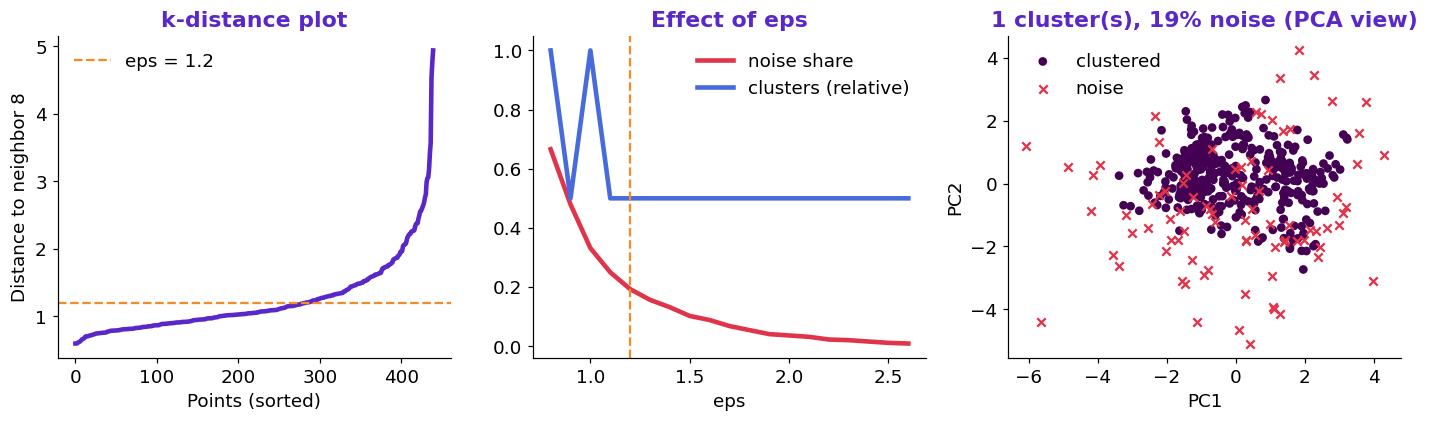

In [8]:
from sklearn.decomposition import PCA

points = PCA(n_components=2, random_state=SEED).fit_transform(X)
is_noise = labels == -1

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(k_distance, color=PURPLE, lw=3)
ax[0].axhline(best_eps, color=ORANGE, ls="--", label=f"eps = {best_eps}")
ax[0].set(title="k-distance plot", xlabel="Points (sorted)", ylabel=f"Distance to neighbor {MIN_SAMPLES}")
ax[0].legend()

ax[1].plot(scan.eps, scan.noise, color=RED, lw=3, label="noise share")
ax[1].plot(scan.eps, scan.clusters / scan.clusters.max(), color=BLUE, lw=3, label="clusters (relative)")
ax[1].axvline(best_eps, color=ORANGE, ls="--")
ax[1].set(title="Effect of eps", xlabel="eps")
ax[1].legend()

ax[2].scatter(points[~is_noise, 0], points[~is_noise, 1], c=labels[~is_noise], cmap="viridis", s=22, label="clustered")
ax[2].scatter(points[is_noise, 0], points[is_noise, 1], c=RED, marker="x", s=30, label="noise")
ax[2].set(title=f"{clusters} cluster(s), {noise_share:.0%} noise (PCA view)", xlabel="PC1", ylabel="PC2")
ax[2].legend()
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "11_dbscan.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "DBSCAN",
    "dataset": "Wholesale Customers (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"eps": best_eps, "Clusters": clusters, "Noise share": round(noise_share, 3)},
}
(results_dir / "11_dbscan.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "DBSCAN",
  "dataset": "Wholesale Customers (UCI)",
  "n_samples": 440,
  "metrics": {
    "eps": 1.2,
    "Clusters": 1,
    "Noise share": 0.193
  }
}


## What to remember
- DBSCAN needs no `k` and it finds outliers.
- It struggles when clusters have very different densities. On this dataset the customers form one broad cloud, and that is a legitimate finding too.